<a href="https://colab.research.google.com/github/danielruizm16/ComputationalMethods/blob/main/Calculus/Homework_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 05: Numerical Calculus.

---
### Teacher: Daniel Ruiz Mejía
### Name: ______
*Computational Methods 2025-II*

---

# 1.
Implement the five-point derivative method through a function called ```five_point_derivative```. Then,
- Calculate the value for $f(x) = \cos(x)$ using an array with 10 data points $[0\leq x\leq 2\pi]$ and plot the derivative.
- Find $f'(\pi/8)$ by varying $h$ and determine the convergence error, comparing your answer with the exact value.
- Determine $f''(\pi/8)$ with $h = 0.05$ and find the error of your approximation. Will it improve with a smaller or larger $h$?

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

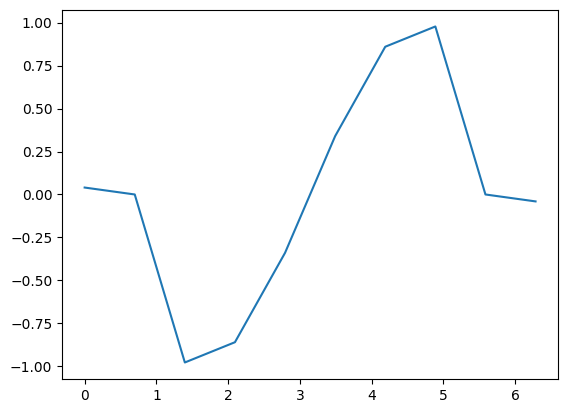

In [ ]:
def five_point_derivative(Y, h):
    n = len(Y)
    d = np.zeros(n)

    d[0] = (-25*Y[0] + 48*Y[1] - 36*Y[2] + 16*Y[3] - 3*Y[4])/(12*h)

    d[-1] = (25*Y[-1] - 48*Y[-2] + 36*Y[-3] - 16*Y[-4] + 3*Y[-5])/(12*h)

    for i in range(2, n-2):
        d[i] = ( Y[i-2] - 8*Y[i-1] + 8*Y[i+1] - Y[i+2] )/(12*h)
    return d

def cos(x):
  return np.cos(x)
def dcos(x):
  return -np.sin(x)
x = np.linspace(0,np.pi*2,10)
h = x[1]-x[0]
Y = cos(x)
plt.plot(x,five_point_derivative(Y,h))

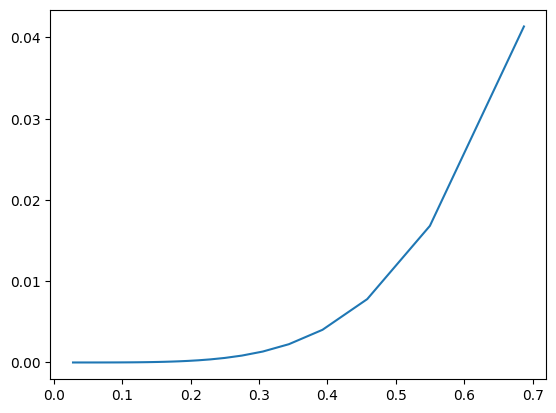

In [ ]:
n = 100
error_derivada = []
h_usadas = []
for i in range(5,n):
  x = np.linspace(np.pi/8,np.pi,i)
  h = x[1]-x[0]
  Y = cos(x)
  error_derivada.append(np.abs(five_point_derivative(Y,h)[0]-dcos(np.pi/8)))
  h_usadas.append(h)
plt.plot(h_usadas,error_derivada)
plt.show()

In [ ]:
x = np.linspace(np.pi/8,np.pi,100)
h = 0.05 #x[1]-x[0]
Y = cos(x)
print("La derivada de la funcion en pi/8 de la derivada numerica es:", five_point_derivative(Y,h)[0])
print("la derivada de la funcion en pi/8 de la derivada analitica es:", dcos(np.pi/8))

La derivada de la funcion en pi/8 de la derivada numerica es: -0.21251634109520723
la derivada de la funcion en pi/8 de la derivada analitica es: -0.3826834323650898


Al disminuir la h se nota que la derivada numerica por alguna razon crece en este caso, y esto tiene sentido ya que al usar la formula de punto inicial, h esta en numerador entonces, al ser tan pequeño y estar dividiendo esta solo va aumentar el valor ya obtenido.

# 2.
The following data is provided for an object's velocity as a function of time:

```
# Time and velocity data
t = np.array([0, 4, 8, 12, 16, 20, 24, 28, 32, 36])  # seconds
v = np.array([0, 34.7, 61.8, 82.8, 99.2, 112.0, 121.9, 129.7, 135.7, 140.4])  # m/s
```
- How far does the object travel from $t = 0$ to $28$ s?
- What is the acceleration of the object at $t = 28$ s? Use Finite Differences and Five-Point Derivative
- What is the acceleration of the object at $t = 30$ s?

In [ ]:
from scipy.interpolate import CubicSpline
def trape_compu_lista(Y, X):
    Y = np.array(Y)
    X = np.array(X)
    integral = 0
    for i in range(len(Y)-1):
        h = X[i+1] - X[i]
        integral += (Y[i] + Y[i+1]) * h / 2
    return integral

In [ ]:
t = np.array([0, 4, 8, 12, 16, 20, 24, 28, 32, 36])  # seconds
v = np.array([0, 34.7, 61.8, 82.8, 99.2, 112.0, 121.9, 129.7, 135.7, 140.4])  # m/s
h = (v[1]-v[0])/len(v)
print("la distancia recorrida en el intervalo de tiempo 0 a 28 segudos es:", trape_compu_lista(v,t))
print("La aceleracion a los 28 segundos es:", five_point_derivative(v,h)[7])
x = np.linspace(30,31,100)
h_1 = x[1]-x[0]
fun = CubicSpline(t,v)(x)
print("La aceleracion a los 30 segundos es:", five_point_derivative(fun,h_1)[0])

la distancia recorrida en el intervalo de tiempo 0 a 28 segudos es: 3392.0
La aceleracion a los 28 segundos es: 1.9692603266090263
La aceleracion a los 30 segundos es: 1.4938305135852235


# 3.

The horizontal surface area $A_s$ (m²) of a lake at a particular depth can be calculated from the volume by differentiation:

$$A_s(z) = -\frac{dV(z)}{dz}$$

where:
- $V$ = volume ($m^3$)
- $z$ = depth (m) measured from the surface down to the bottom.


The average concentration of a substance that varies with depth $c$ ($g/m^3$) can be calculated by integration:

$$c = \frac{\int_0^Z c(z)A_s(z) dz}{V_T}$$

where:
- $Z$ = total depth (m)
- $V_T$ = total volume of the lake, also given by:


$$V_T = \int_0^Z A_s(z) dz$$

Based on the following data, determine the average concentration.
```
# Provided data
z = np.array([0, 4, 8, 12, 16])  # depth in meters
V = np.array([9.8175, 5.1051, 1.9635, 0.3927, 0.0000]) * 1e6  # volume in m³
c = np.array([10.2, 8.5, 7.4, 5.2, 4.1])  # concentration in g/m³

# Important parameters
Z = z[-1]  # total depth (16 m)
```

In [ ]:
z = np.array([0, 4, 8, 12, 16])  # depth in meters
V = np.array([9.8175, 5.1051, 1.9635, 0.3927, 0.0000]) * 1e6  # volume in m³
c = np.array([10.2, 8.5, 7.4, 5.2, 4.1])  # concentration in g/m³
As = -np.gradient(V, z)  # m²
VT = np.trapz(As, z)
c_avg = np.trapz(c * As, z) / VT
print("concentración promedio c_avg:", c_avg)

concentración promedio c_avg: 8.226


/tmp/ipython-input-4048239549.py:5: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  VT = np.trapz(As, z)
/tmp/ipython-input-4048239549.py:6: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  c_avg = np.trapz(c * As, z) / VT


# 4.
Boole's rule and Weddle's rule are numerical integration methods that use higher-order polynomial approximations. Write Python functions to implement both rules and compare their performance.

**Boole's Rule**
Uses 5 points (4th degree polynomial):
$$
\int_a^b f(x)dx \approx \frac{2h}{45}[7f(x_0) + 32f(x_1) + 12f(x_2) + 32f(x_3) + 7f(x_4)]
$$
where $h = \frac{b-a}{4}$ and $x_i = a + i\cdot h$


**Weddle's Rule**
Uses 7 points (6th degree polynomial):
$$
\int_a^b f(x)dx \approx \frac{3h}{10}[f(x_0) + 5f(x_1) + f(x_2) + 6f(x_3) + f(x_4) + 5f(x_5) + f(x_6)]
$$
where $h = \frac{b-a}{6}$ and $x_i = a + i\cdot h$

- Implement the functions ```boole_rule(f, a, b)``` and ```weddle_rule(f, a, b)``` that approximate $\int_a^b f(x)dx$ using the formulas above.
- Test your functions on:

    - $\int_0^{\pi/4}  e^{3x}\cdot \sin(x) \, dx = \frac{1}{10}\left(1+\sqrt{2}e^{3\pi/4} \right)$

    - $\int_e^{1+e} \frac{1}{x\ln x} \, dx =\ln{(\ln{(1+e)})}$
- Compare the accuracy for both methods and both integrals by computing the relative error:
- For $\int_0^{\pi} \sin(x)dx=2$, try using the composite version of each rule by dividing the interval into 3 different subintervals and observe how the error decreases.

In [ ]:
def boole_rule(f, a, b):
    h = (b - a) / 4
    x0 = a
    x1 = a + h
    x2 = a + 2*h
    x3 = a + 3*h
    x4 = b
    return (2*h/45) * (7*f(x0) + 32*f(x1) + 12*f(x2) + 32*f(x3) + 7*f(x4))
def weddle_rule(f, a, b):
    h = (b - a) / 6
    x = [a + i*h for i in range(7)]
    return (3*h/10) * (f(x[0]) + 5*f(x[1]) + f(x[2]) + 6*f(x[3]) + f(x[4]) + 5*f(x[5]) + f(x[6]))

In [ ]:
f_1 = lambda x: np.exp(3*x) * np.sin(x)
f_2 = lambda x: (1/x) * np.log(x)
exact1 = (1/10)*(np.exp(3*np.pi/4)*(2 - np.sqrt(2)) - 1)
exact2 = np.log(np.log(1 + np.e))
I1_boole = boole_rule(f_1, 0, np.pi/4)
I2_boole = boole_rule(f_2, 1, 1 + np.e)
I1_weddle = weddle_rule(f_1, 0, np.pi/4)
I2_weddle = weddle_rule(f_2, 1, 1 + np.e)
err1_boole = abs(I1_boole - exact1)/abs(exact1)
err1_weddle = abs(I1_weddle - exact1)/abs(exact1)
err2_boole = abs(I2_boole - exact2)/abs(exact2)
err2_weddle = abs(I2_weddle - exact2)/abs(exact2)

print("Integral 1 Boole =", I1_boole, "Error relativo =", err1_boole)
print("Integral 1 Weddle =", I1_weddle, "Error relativo =", err1_weddle)
print("Integral 2 Boole =", I2_boole, "Error relativo =", err2_boole)
print("Integral 2 Weddle =", I2_weddle, "Error relativo =", err2_weddle)


Integral 1 Boole = 1.5923263323561376 Error relativo = 2.0737095350962518
Integral 1 Weddle = 1.5921093348540487 Error relativo = 2.073290659092188
Integral 2 Boole = 0.8584288930740054 Error relativo = 2.1500373173316856
Integral 2 Weddle = 0.8616944779654281 Error relativo = 2.16202050470328


# 5.
The wave function of the electron in the 2s state ($n=2$, $l=0$, $m=0$) in dimensionless radial units is:

$$\psi_{200}(r,\theta,\varphi) = \frac{1}{4\sqrt{2\pi}} (2 - r) e^{-r/2}$$

The probability of finding the electron between $r=0$ and $r=R$ is given by:

$$P(R) = \frac{1}{8} \int_0^R r^2 (2 - r)^2 e^{-r} dr$$

where the angular integrals contribute a factor of $4\pi$.

- Calculate the probabilities $P(R)$ for $R \in [10,25]$ with increments of 1 using the methods:
    - Trapezoidal
    - Simpson
    - Gaussian Quadrature
    
Ensuring that the tolerance is less than $\varepsilon = 10^{-6}$

- Calculate the radial integral from $r=0$ to $+\infty$, verify that the total probability is 1.

In [ ]:
def f(r):
    return r**2 * (2 - r)**2 * np.exp(-r)
def integrand(r):
    return f(r) / 8

In [ ]:
def trapezoide_adaptativo(func, a, b, tolerancia=1e-6, max_iteraciones=20):
    n = 1
    I_1 = (b - a)/2 * (func(a) + func(b))
    for _ in range(max_iteraciones):
        n *= 2
        h = (b - a) / n
        x_mid = a + h/2 + np.arange(n-1)*h
        I_2 = I_1/2 + h * np.sum(func(a + (np.arange(1, n, 2)*h)))
        if abs(I_2 - I_1) < tolerancia:
            return I_2
        I_1 = I_2
    return I_2


In [ ]:
def simpson_adaptive(func, a, b, tol=1e-6, max_iteraciones=20):
    n = 2
    h = (b - a) / n
    I_1 = h/3 * (func(a) + 4*func(a + h) + func(b))
    for _ in range(max_iteraciones):
        n *= 2
        if n % 2 != 0:
            n += 1
        h = (b - a) / n
        x = np.linspace(a, b, n+1)
        I_2 = h/3 * (func(x[0]) + func(x[-1]) + 4*np.sum(func(x[1:-1:2])) + 2*np.sum(func(x[2:-2:2])))
        if abs(I_2 - I_1) < tol:
            return I_2
        I_1 = I_2
    return I_2

In [ ]:
from scipy.integrate import quad

def gaussian(func, a, b):
    result, _ = quad(func, a, b, epsabs=1e-6)
    return result
R_values = np.arange(10, 26, 1)

P_trap = [trapezoide_adaptativo(integrand, 0, R) for R in R_values]
P_simp = [simpson_adaptive(integrand, 0, R) for R in R_values]
P_gauss = [gaussian(integrand, 0, R) for R in R_values]

# Mostrar resultados
for i, R in enumerate(R_values):
    print(f"R={R}: Trapezoid={P_trap[i]:.8f}, Simpson={P_simp[i]:.8f}, Gaussian={P_gauss[i]:.8f}")
P_total = gaussian(integrand, 0, np.inf)
print("Probabilidad total (0→∞):", P_total)

R=10: Trapezoid=0.94048053, Simpson=0.94048070, Gaussian=0.94048069
R=11: Trapezoid=0.96822281, Simpson=0.96822293, Gaussian=0.96822293
R=12: Trapezoid=0.98355162, Simpson=0.98355195, Gaussian=0.98355194
R=13: Trapezoid=0.99170749, Simpson=0.99170771, Gaussian=0.99170770
R=14: Trapezoid=0.99591291, Simpson=0.99591305, Gaussian=0.99591304
R=15: Trapezoid=0.99802482, Simpson=0.99802493, Gaussian=0.99802490
R=16: Trapezoid=0.99906174, Simpson=0.99906183, Gaussian=0.99906179
R=17: Trapezoid=0.99956102, Simpson=0.99956110, Gaussian=0.99956106
R=18: Trapezoid=0.99979737, Simpson=0.99979745, Gaussian=0.99979740
R=19: Trapezoid=0.99990758, Simpson=0.99990767, Gaussian=0.99990761
R=20: Trapezoid=0.99995830, Simpson=0.99995833, Gaussian=0.99995832
R=21: Trapezoid=0.99998136, Simpson=0.99998139, Gaussian=0.99998138
R=22: Trapezoid=0.99999173, Simpson=0.99999177, Gaussian=0.99999176
R=23: Trapezoid=0.99999635, Simpson=0.99999639, Gaussian=0.99999638
R=24: Trapezoid=0.99999838, Simpson=0.99999843, 